# NYC Yellow Taxi Fare Prediction — Pre-trip vs Post-trip (3 Boosting Algorithms)

This notebook compares **XGBoost, LightGBM, and CatBoost**, each trained for **pre-trip** and **post-trip** fare prediction (six models total). Start with 100,000 rows, then optionally use the full file. Each code section includes explanatory `#` comments.

**Important:** Pre-trip predictions use only pickup time and pickup/drop-off taxi zones. Actual distance and duration are used **only** after the trip. This is a retrospective comparison on one month of trips; post-trip inputs are not available for advance quotes.


## Step 1 — Install libraries, upload file, and explore the data

In [1]:
# Install Parquet support and all three gradient-boosting libraries in Google Colab.
%pip -q install -U pyarrow lightgbm xgboost catboost scikit-learn matplotlib pandas numpy


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [2]:
# Upload the NYC taxi Parquet file from your computer into this Colab session.
from google.colab import files
from pathlib import Path
uploaded = files.upload()
if not uploaded:
    raise ValueError("No file uploaded. Please upload yellow_tripdata_2026-05.parquet.")
file_name = next((name for name in uploaded if name.endswith('.parquet')), None)
if file_name is None:
    raise ValueError("Please upload a .parquet file.")
print("Selected file:", file_name)

Saving yellow_tripdata_2026-05.parquet to yellow_tripdata_2026-05.parquet
Selected file: yellow_tripdata_2026-05.parquet


In [3]:
# Read a small sample first to test the pipeline; switch to True for the whole file later.
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

LOAD_FULL_DATA = False
SAMPLE_ROWS = 100_000

parquet_file = pq.ParquetFile(file_name)
print(f"Total rows in file: {parquet_file.metadata.num_rows:,}")
if LOAD_FULL_DATA:
    df = pd.read_parquet(file_name)
else:
    # Read row groups until we have enough rows, then keep the first SAMPLE_ROWS.
    chunks = []
    rows_read = 0
    for batch in parquet_file.iter_batches(batch_size=min(SAMPLE_ROWS, 100_000)):
        chunk = batch.to_pandas()
        chunks.append(chunk)
        rows_read += len(chunk)
        if rows_read >= SAMPLE_ROWS:
            break
    df = pd.concat(chunks, ignore_index=True).head(SAMPLE_ROWS)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns")
display(df.head(10))
print("Column names:", df.columns.tolist())
print("Data types:")
df.info()

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Total rows in file: 4,090,836
Loaded 100,000 rows and 20 columns


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1,7.51,1,N,138,37,2,35.9,6.00,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1,6.14,1,N,138,237,1,27.5,6.00,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1,2.40,1,N,249,232,1,19.1,4.25,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0,1.20,1,N,232,114,1,9.3,4.25,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2,0.86,1,N,140,237,1,7.2,0.00,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00
5,2,2026-05-01 00:24:35,2026-05-01 00:49:55,1,5.89,1,N,255,236,1,28.9,1.00,0.5,6.78,0.0,1.0,40.68,2.5,0.0,0.00
6,1,2026-05-01 00:06:08,2026-05-01 00:12:47,1,1.60,1,N,43,239,1,9.3,3.50,0.5,2.85,0.0,1.0,17.15,2.5,0.0,0.00
7,2,2026-05-01 00:49:20,2026-05-01 01:06:36,1,3.84,1,N,164,88,1,19.8,1.00,0.5,1.00,0.0,1.0,26.55,2.5,0.0,0.75
8,2,2026-05-01 00:29:38,2026-05-01 00:32:49,1,0.61,1,N,234,164,1,5.8,1.00,0.5,3.46,0.0,1.0,15.01,2.5,0.0,0.75
9,2,2026-05-01 00:39:07,2026-05-01 00:48:32,1,1.98,1,N,234,144,1,11.4,1.00,0.5,4.29,0.0,1.0,21.44,2.5,0.0,0.75


Column names: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']
Data types:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               100000 non-null  int32         
 1   tpep_pickup_datetime   100000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  100000 non-null  datetime64[us]
 3   passenger_count        100000 non-null  int64         
 4   trip_distance          100000 non-null  float64       
 5   RatecodeID             100000 non-null  int64         
 6   store_and_fwd_flag     100000 non-null  s

In [4]:
# Summarize missing values and numerical columns to understand data quality.
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (100 * df.isna().mean()).round(2)
}).sort_values('missing_count', ascending=False)
display(missing)
display(df.describe(include='all').transpose())

,missing_count,missing_percent
VendorID,0,0.0
tpep_pickup_datetime,0,0.0
tpep_dropoff_datetime,0,0.0
passenger_count,0,0.0
trip_distance,0,0.0
RatecodeID,0,0.0
store_and_fwd_flag,0,0.0
PULocationID,0,0.0
DOLocationID,0,0.0
payment_type,0,0.0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
VendorID,100000.0,NaN,NaN,NaN,1.84418,1.0,2.0,2.0,2.0,7.0,0.770614
tpep_pickup_datetime,100000,NaN,NaN,NaN,2026-05-01 14:24:11.176710,2026-04-30 23:47:18,2026-05-01 10:55:57.750000,2026-05-01 15:13:48.500000,2026-05-01 18:34:04,2026-05-02 01:56:05,NaN
tpep_dropoff_datetime,100000,NaN,NaN,NaN,2026-05-01 14:43:34.841460,2026-04-30 23:53:05,2026-05-01 11:15:08.750000,2026-05-01 15:37:28.500000,2026-05-01 18:51:31.250000,2026-05-04 10:48:22,NaN
passenger_count,100000.0,NaN,NaN,NaN,1.22875,0.0,1.0,1.0,1.0,6.0,0.62028
trip_distance,100000.0,NaN,NaN,NaN,3.325795,0.0,0.97,1.65,3.28,78.87,4.428704
RatecodeID,100000.0,NaN,NaN,NaN,6.6574,1.0,1.0,1.0,1.0,99.0,22.684564
store_and_fwd_flag,100000,2,N,99925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PULocationID,100000.0,NaN,NaN,NaN,166.63082,1.0,132.0,162.0,235.0,265.0,64.828825
DOLocationID,100000.0,NaN,NaN,NaN,164.59182,1.0,114.0,162.0,236.0,265.0,69.651327
payment_type,100000.0,NaN,NaN,NaN,1.15113,1.0,1.0,1.0,1.0,4.0,0.428126


## Step 2 — Clean the data

We keep trips with plausible **positive** fares, distances, and durations. These thresholds are project assumptions, not official TLC quality rules. They remove unusual trips too, so report the number excluded. The **same filtered trips** are used for both models.

In [5]:
# Make a working copy so the original uploaded data stays unchanged.
data = df.copy()
required = ['fare_amount', 'trip_distance', 'tpep_pickup_datetime',
            'tpep_dropoff_datetime', 'PULocationID', 'DOLocationID']
missing_columns = [c for c in required if c not in data.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from this Parquet file: {missing_columns}")

# Convert dates and numeric measurements into consistent formats.
for c in ['tpep_pickup_datetime', 'tpep_dropoff_datetime']:
    data[c] = pd.to_datetime(data[c], errors='coerce')
for c in ['fare_amount', 'trip_distance', 'PULocationID', 'DOLocationID']:
    data[c] = pd.to_numeric(data[c], errors='coerce')

# Actual trip duration is known only AFTER a trip has finished.
data['trip_duration_minutes'] = (
    (data['tpep_dropoff_datetime'] - data['tpep_pickup_datetime']).dt.total_seconds() / 60
)

# Keep valid completed trips and limit extreme values for a first experiment.
valid = (
    data[required].notna().all(axis=1)
    & data['fare_amount'].between(0.01, 500)
    & data['trip_distance'].between(0.01, 150)
    & data['trip_duration_minutes'].between(1, 240)
    & data['PULocationID'].between(1, 265)
    & data['DOLocationID'].between(1, 265)
)
clean = data.loc[valid].copy()
print(f"Rows before cleaning: {len(data):,}")
print(f"Rows after cleaning:  {len(clean):,}")
print(f"Rows excluded:        {len(data)-len(clean):,}")
if len(clean) < 100:
    raise ValueError('Too few valid rows after cleaning. Check column values and thresholds.')

Rows before cleaning: 100,000
Rows after cleaning:  96,369
Rows excluded:        3,631


## Step 3 — Select and engineer features

**Pre-trip features:** pickup zone, drop-off zone, pickup hour, weekday, weekend flag, and month. **Post-trip features:** all pre-trip features **plus** recorded distance and trip duration. We intentionally exclude `total_amount`, tips, taxes, tolls, and other payment outcomes to avoid target leakage.

In [6]:
# Extract useful time features from the pickup timestamp.
clean['pickup_hour'] = clean['tpep_pickup_datetime'].dt.hour
clean['pickup_dayofweek'] = clean['tpep_pickup_datetime'].dt.dayofweek
clean['pickup_month'] = clean['tpep_pickup_datetime'].dt.month
clean['is_weekend'] = (clean['pickup_dayofweek'] >= 5).astype('int8')

# Treat taxi-zone IDs as categories rather than continuous measurements.
for c in ['PULocationID', 'DOLocationID']:
    clean[c] = clean[c].astype('int16').astype('category')

# Separate the two feature sets; both predict exactly the same target.
pre_features = ['PULocationID', 'DOLocationID', 'pickup_hour',
                'pickup_dayofweek', 'pickup_month', 'is_weekend']
post_features = pre_features + ['trip_distance', 'trip_duration_minutes']
target = 'fare_amount'
print('Pre-trip features:', pre_features)
print('Post-trip features:', post_features)

Pre-trip features: ['PULocationID', 'DOLocationID', 'pickup_hour', 'pickup_dayofweek', 'pickup_month', 'is_weekend']
Post-trip features: ['PULocationID', 'DOLocationID', 'pickup_hour', 'pickup_dayofweek', 'pickup_month', 'is_weekend', 'trip_distance', 'trip_duration_minutes']


/tmp/ipykernel_7996/351111259.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  clean['pickup_dayofweek'] = clean['tpep_pickup_datetime'].dt.dayofweek


## Step 4 — Split into training, validation, and test sets

Sort by pickup time and use the earliest 70% for training, next 15% for validation, and latest 15% for testing. This is more realistic than a random split. We use **the exact same rows** for both models. With only one month of data, this does not test generalization to other seasons.

In [7]:
# Chronological split: no shuffling, and no model sees later trips while training.
clean = clean.sort_values('tpep_pickup_datetime').reset_index(drop=True)
n = len(clean)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)
train_idx = np.arange(0, train_end)
valid_idx = np.arange(train_end, valid_end)
test_idx = np.arange(valid_end, n)

y_train = clean.loc[train_idx, target]
y_valid = clean.loc[valid_idx, target]
y_test = clean.loc[test_idx, target]
print(f'Train: {len(train_idx):,} | Validation: {len(valid_idx):,} | Test: {len(test_idx):,}')
print('Train dates:', clean.loc[train_idx, 'tpep_pickup_datetime'].min(), 'to', clean.loc[train_idx, 'tpep_pickup_datetime'].max())
print('Test dates:', clean.loc[test_idx, 'tpep_pickup_datetime'].min(), 'to', clean.loc[test_idx, 'tpep_pickup_datetime'].max())

Train: 67,458 | Validation: 14,455 | Test: 14,456
Train dates: 2026-04-30 23:47:18 to 2026-05-01 17:58:57
Test dates: 2026-05-01 19:54:58 to 2026-05-02 01:56:05


## Step 5 — Train baseline and six boosting models

Fit **LightGBM**, **XGBoost**, and **CatBoost** on both pre-trip and post-trip features. All use the same chronological train and validation rows. Model hyperparameters differ by library because the algorithms are not identical. Categorical zone IDs are handled natively, without treating them as ordered numbers.


In [8]:
# Import the three boosting libraries and a simple median-fare baseline.
import time
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.dummy import DummyRegressor

# Both approaches use the same target and chronological train/validation/test split.
feature_sets = {'Pre-trip': pre_features, 'Post-trip': post_features}
zone_columns = ['PULocationID', 'DOLocationID']

# Prepare inputs for each algorithm. LightGBM and XGBoost accept pandas
# categorical columns; CatBoost expects categorical values as strings.
def make_inputs(features, algorithm):
    X = clean[features].copy()
    if algorithm == 'CatBoost':
        for col in zone_columns:
            X[col] = X[col].astype(str)
    return (X.iloc[train_idx], X.iloc[valid_idx], X.iloc[test_idx])

# Baseline: always predict the median fare in the training period.
baseline = DummyRegressor(strategy='median')
baseline.fit(clean.loc[train_idx, pre_features], y_train)

# Fit each model on training trips; use validation trips for early stopping.
# Training six models can take several minutes on Colab CPU.
models = {}
training_times = {}
for algorithm in ['LightGBM', 'XGBoost', 'CatBoost']:
    for approach, features in feature_sets.items():
        X_train, X_valid, _ = make_inputs(features, algorithm)
        start = time.perf_counter()
        if algorithm == 'LightGBM':
            model = lgb.LGBMRegressor(
                objective='regression', n_estimators=600, learning_rate=0.05,
                num_leaves=31, random_state=42, n_jobs=-1, verbosity=-1
            )
            model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
                      eval_metric='l1', categorical_feature=zone_columns,
                      callbacks=[lgb.early_stopping(40, verbose=False)])
        elif algorithm == 'XGBoost':
            model = xgb.XGBRegressor(
                objective='reg:squarederror', n_estimators=600, learning_rate=0.05,
                max_depth=6, tree_method='hist', enable_categorical=True,
                early_stopping_rounds=40, eval_metric='mae',
                random_state=42, n_jobs=-1
            )
            model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
        else:
            model = CatBoostRegressor(
                iterations=600, learning_rate=0.05, depth=6,
                loss_function='RMSE', eval_metric='MAE',
                random_seed=42, verbose=False, thread_count=-1
            )
            model.fit(X_train, y_train, cat_features=zone_columns,
                      eval_set=(X_valid, y_valid), early_stopping_rounds=40,
                      verbose=False)
        key = (algorithm, approach)
        models[key] = model
        training_times[key] = time.perf_counter() - start
        print(f'{algorithm} | {approach}: trained in {training_times[key]:.1f} seconds')


/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM | Pre-trip: trained in 3.1 seconds


/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM | Post-trip: trained in 1.5 seconds
XGBoost | Pre-trip: trained in 6.1 seconds
XGBoost | Post-trip: trained in 4.2 seconds
CatBoost | Pre-trip: trained in 17.4 seconds
CatBoost | Post-trip: trained in 26.8 seconds


## Step 6 — Evaluate on the held-out test period

Compare **MAE**, **RMSE**, **R²**, and training time across all six models and the median baseline. Do not use the test set for model tuning.


In [9]:
# Predict fares for the same unseen test trips using each trained model.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

predictions = {}
results = []
baseline_pred = baseline.predict(clean.loc[test_idx, pre_features])
predictions['Median baseline'] = baseline_pred
results.append({'Algorithm': 'Median baseline', 'Approach': 'Pre-trip',
                'MAE ($)': mean_absolute_error(y_test, baseline_pred),
                'RMSE ($)': np.sqrt(mean_squared_error(y_test, baseline_pred)),
                'R²': r2_score(y_test, baseline_pred), 'Train seconds': np.nan})

for (algorithm, approach), model in models.items():
    _, _, X_test = make_inputs(feature_sets[approach], algorithm)
    pred = model.predict(X_test)
    predictions[(algorithm, approach)] = pred
    results.append({'Algorithm': algorithm, 'Approach': approach,
                    'MAE ($)': mean_absolute_error(y_test, pred),
                    'RMSE ($)': np.sqrt(mean_squared_error(y_test, pred)),
                    'R²': r2_score(y_test, pred),
                    'Train seconds': training_times[(algorithm, approach)]})

# Lower MAE/RMSE and higher R² indicate better predictive performance.
results_df = pd.DataFrame(results).sort_values('MAE ($)').reset_index(drop=True)
display(results_df.round(3))

# Show how much post-trip information reduces MAE for each algorithm.
for algorithm in ['LightGBM', 'XGBoost', 'CatBoost']:
    pre_mae = mean_absolute_error(y_test, predictions[(algorithm, 'Pre-trip')])
    post_mae = mean_absolute_error(y_test, predictions[(algorithm, 'Post-trip')])
    print(f'{algorithm}: post-trip MAE improvement = ${pre_mae - post_mae:.2f}')


,Algorithm,Approach,MAE ($),RMSE ($),R²,Train seconds
0,XGBoost,Post-trip,0.954,3.904,0.938,4.156
1,LightGBM,Post-trip,0.972,3.489,0.951,1.510
2,CatBoost,Post-trip,0.997,3.646,0.946,26.849
3,XGBoost,Pre-trip,3.769,7.144,0.794,6.090
4,LightGBM,Pre-trip,3.792,6.908,0.807,3.130
5,CatBoost,Pre-trip,4.431,8.244,0.725,17.368
6,Median baseline,Pre-trip,9.177,16.307,-0.075,NaN


LightGBM: post-trip MAE improvement = $2.82
XGBoost: post-trip MAE improvement = $2.82
CatBoost: post-trip MAE improvement = $3.43


## Step 7 — Optional hyperparameter tuning on validation data

The initial comparison trains all six models. Optionally test a small range of **tree depths** for each algorithm and approach using **validation MAE only**. This cell does not change the models already evaluated in Step 6; it reports candidate settings for a later, separate final training run.


In [10]:
# Set True to run an additional six-times-two depth comparison (slower).
RUN_TUNING = False
if RUN_TUNING:
    from sklearn.metrics import mean_absolute_error
    tuning_results = []
    for algorithm in ['LightGBM', 'XGBoost', 'CatBoost']:
        for approach, features in feature_sets.items():
            X_train, X_valid, _ = make_inputs(features, algorithm)
            for depth in [4, 8]:
                if algorithm == 'LightGBM':
                    candidate = lgb.LGBMRegressor(
                        n_estimators=400, learning_rate=0.05, max_depth=depth,
                        num_leaves=min(31, 2**depth - 1), verbosity=-1,
                        random_state=42, n_jobs=-1)
                    candidate.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
                                  categorical_feature=zone_columns,
                                  callbacks=[lgb.early_stopping(30, verbose=False)])
                elif algorithm == 'XGBoost':
                    candidate = xgb.XGBRegressor(
                        n_estimators=400, learning_rate=0.05, max_depth=depth,
                        tree_method='hist', enable_categorical=True,
                        eval_metric='mae', early_stopping_rounds=30,
                        random_state=42, n_jobs=-1)
                    candidate.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
                else:
                    candidate = CatBoostRegressor(
                        iterations=400, learning_rate=0.05, depth=depth,
                        loss_function='RMSE', eval_metric='MAE',
                        random_seed=42, verbose=False)
                    candidate.fit(X_train, y_train, cat_features=zone_columns,
                                  eval_set=(X_valid, y_valid),
                                  early_stopping_rounds=30, verbose=False)
                val_mae = mean_absolute_error(y_valid, candidate.predict(X_valid))
                tuning_results.append({'Algorithm': algorithm, 'Approach': approach,
                                       'Depth': depth, 'Validation MAE ($)': val_mae})
    tuning_df = pd.DataFrame(tuning_results)
    display(tuning_df.sort_values(['Algorithm', 'Approach', 'Validation MAE ($)']).round(3))
    print('Choose settings using validation MAE, then retrain and evaluate once on the test set.')
else:
    print('Tuning skipped. Set RUN_TUNING = True to try alternative tree depths.')


Tuning skipped. Set RUN_TUNING = True to try alternative tree depths.


## Step 8 — Interpret and visualize predictions

Plot feature importance and predicted-versus-actual fares for **all six** models. Importance values are model-specific and should not be compared numerically across different algorithms.


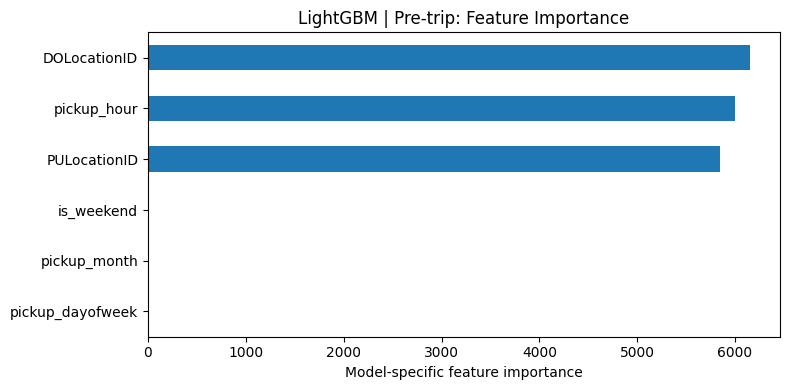

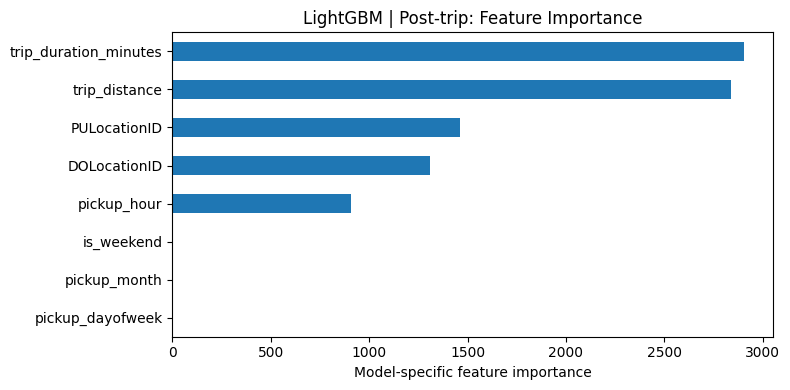

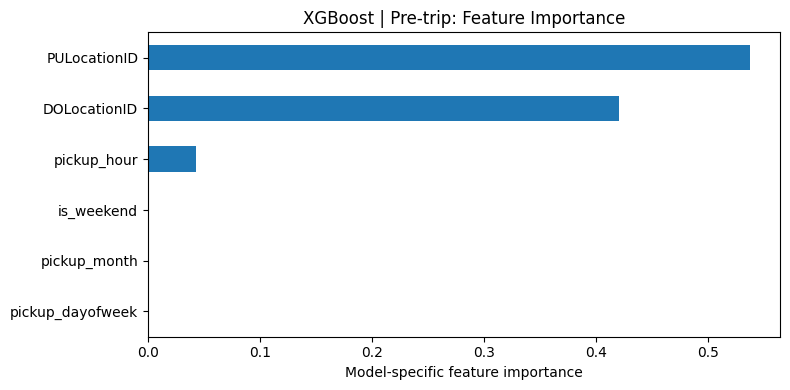

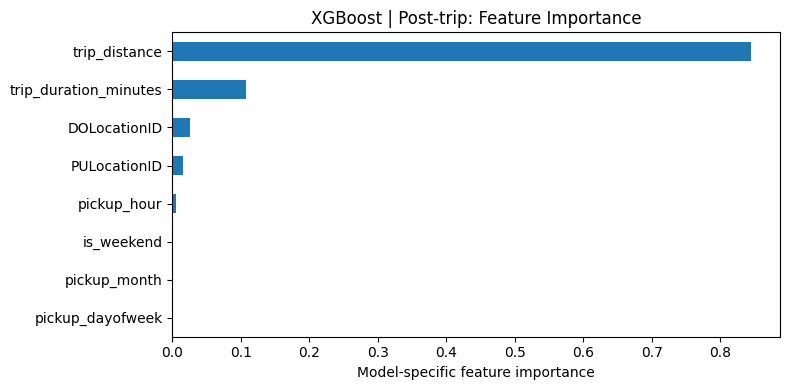

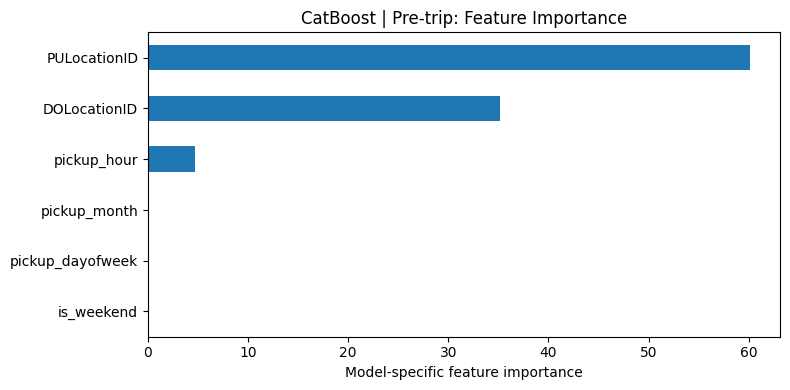

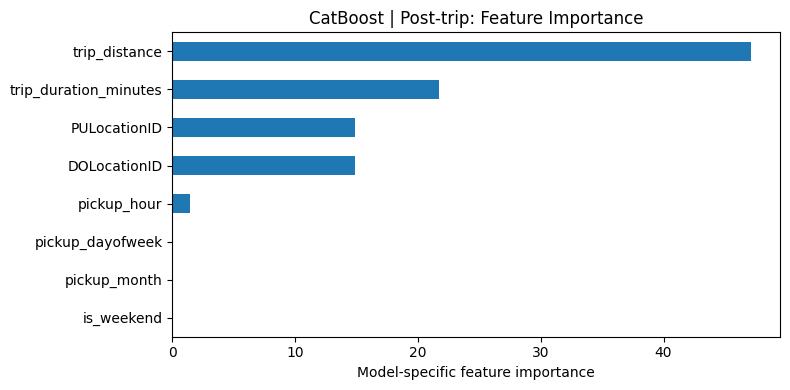

In [11]:
# Plot feature importance separately for each algorithm and approach.
import matplotlib.pyplot as plt
for (algorithm, approach), model in models.items():
    features = feature_sets[approach]
    importance = pd.Series(model.feature_importances_, index=features).sort_values()
    plt.figure(figsize=(8, 4))
    importance.plot(kind='barh')
    plt.title(f'{algorithm} | {approach}: Feature Importance')
    plt.xlabel('Model-specific feature importance')
    plt.tight_layout()
    plt.show()


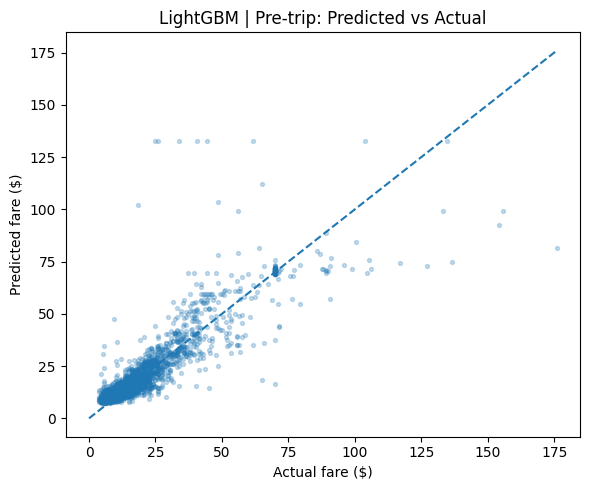

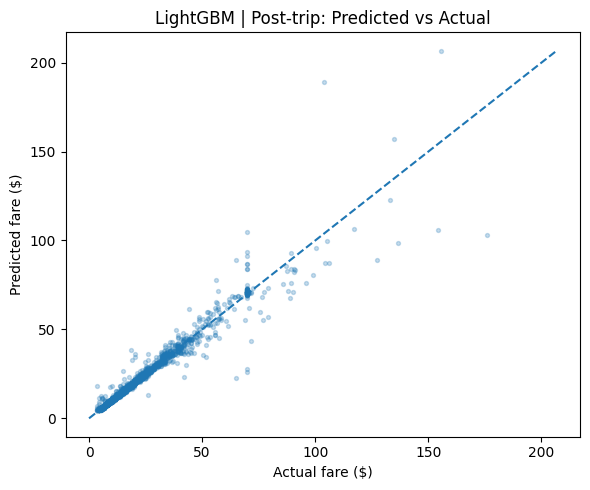

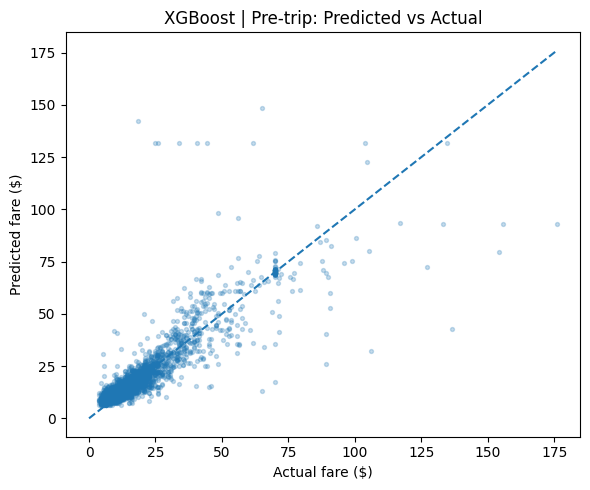

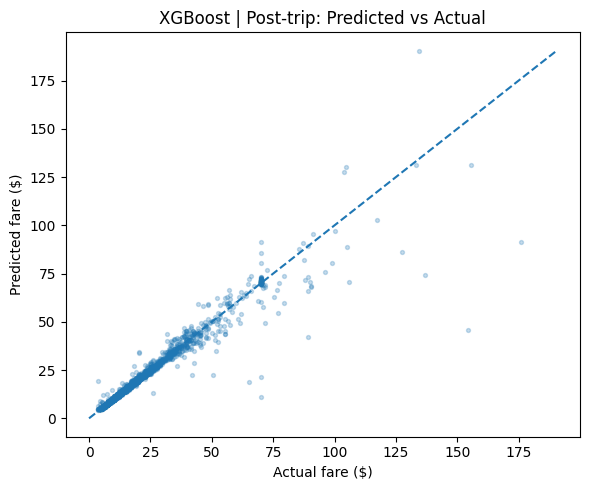

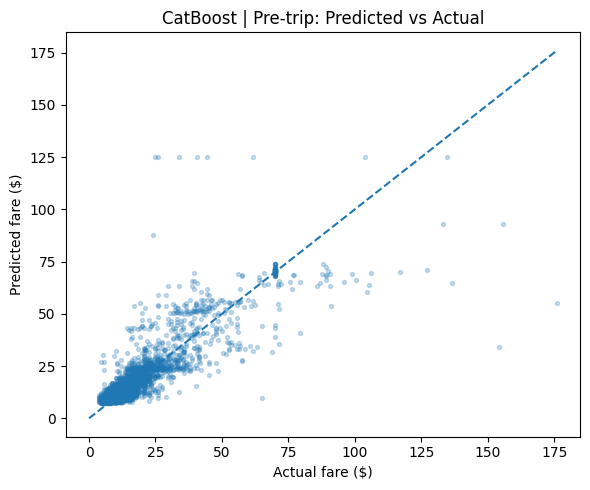

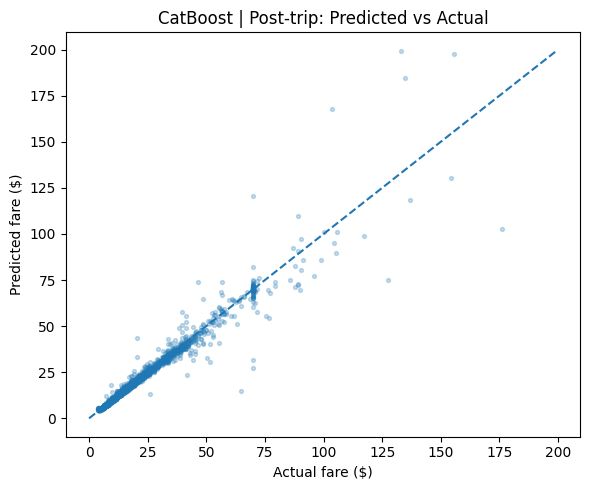

In [12]:
# Plot actual vs predicted fares for up to 3,000 held-out trips per model.
# Points near the dashed diagonal represent accurate predictions.
plot_count = min(3000, len(y_test))
actual = y_test.to_numpy()[:plot_count]
for key, pred_all in predictions.items():
    if not isinstance(key, tuple):
        continue
    algorithm, approach = key
    pred = pred_all[:plot_count]
    plt.figure(figsize=(6, 5))
    plt.scatter(actual, pred, alpha=0.25, s=8)
    max_value = max(float(actual.max()), float(pred.max()))
    plt.plot([0, max_value], [0, max_value], linestyle='--')
    plt.xlabel('Actual fare ($)')
    plt.ylabel('Predicted fare ($)')
    plt.title(f'{algorithm} | {approach}: Predicted vs Actual')
    plt.tight_layout()
    plt.show()


## Next steps

1. Run with `LOAD_FULL_DATA = False` and `SAMPLE_ROWS = 100_000` to check all six models.
2. Compare MAE, RMSE, R², and training time on the held-out test data.
3. If needed, tune on the **validation** period, not the test period.
4. Set `LOAD_FULL_DATA = True` and rerun from Step 1 to train on all available trips (more RAM and time required).
5. For a true pre-trip distance-based model, obtain a route-distance estimate from information available before departure; never use the recorded actual distance.
